In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import warnings
from pytablericons import TablerIcons, OutlineIcon
warnings.filterwarnings("ignore")

# Cores utilizadas
CORES = {
    "laranja": "#E07A3D",
    "azul": "#2E5A88",
    "verde": "#3A7D5C",
    "roxo": "#6B4C9A",
    "cinza": "#5A5A5A",
    "cinza_claro": "#E8E8E8",
    "fundo": "#FAFAFA",
    "texto": "#222222",
}

# Gráfico de Ícones

O objetivo desse gráfico é apresentar visualmente os principais diferenciais e vantagens do dispositivo EEG proposto no artigo "Development and Validation of an Affordable Wearable Multichannel EEG System With Active Electrodes and Innovative Flexible Headbands (Antolínez et al., 2025)", destacando seus benefícios em relação aos sistemas comerciais existentes. Para fazer os ícones, fopi utilizada a biblioteca pytablericons, e importado ícones do sinal de dólar, energia, Wifi, crosshair e microscópio. Além disso, foram utilizado círculos em diferentes cores e uma barra lateral para decoração.

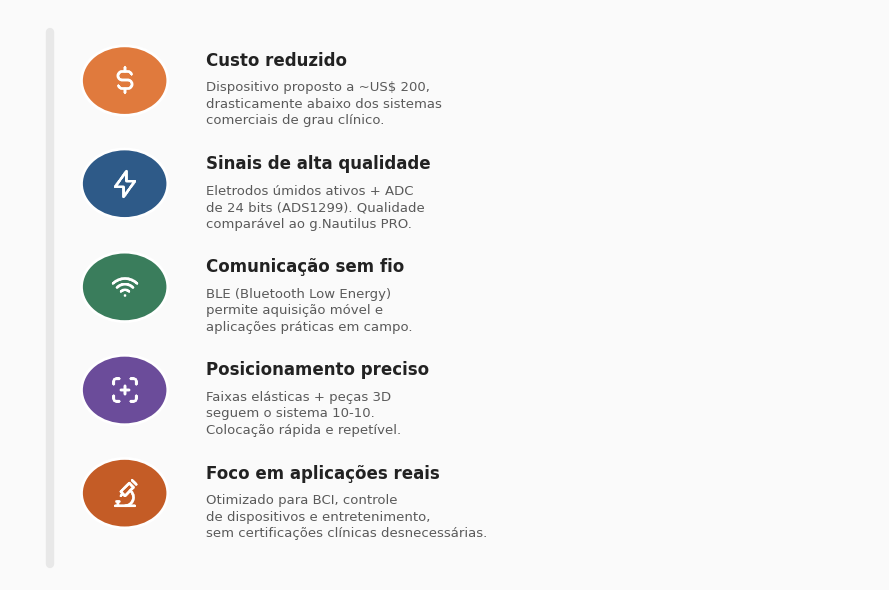

In [2]:
# Ícones

def desenhar_icone_circulo(ax, x, y, icone, cor, tamanho = 0.35):
    # Círculo de fundo
    circ = Circle((x, y), tamanho, facecolor = cor, edgecolor = "white", linewidth = 2, zorder = 3)
    ax.add_patch(circ)

    # Carregar ícone Tabler
    imagem_icone = TablerIcons.load(icone, size = 64, color = "#FFFFFF", stroke_width = 2)

    # Converter para elemento visual do Matplotlib
    imagem = OffsetImage(imagem_icone, zoom = 0.38)

    anotacao = AnnotationBbox(imagem, (x, y), frameon = False, box_alignment = (0.5, 0.5), zorder = 4)
    ax.add_artist(anotacao)


def painel_icones():
    fig, ax = plt.subplots(figsize=(9, 6))

    # Remover margens externas da figura
    fig.patch.set_facecolor(CORES["fundo"])
    ax.set_facecolor(CORES["fundo"])

    fig.patch.set_facecolor(CORES["fundo"])

    # Ícones e textos
    itens = [
        {
            "icone": OutlineIcon.CURRENCY_DOLLAR,
            "cor": CORES["laranja"],
            "titulo": "Custo reduzido",
            "texto": "Dispositivo proposto a ~US$ 200,\ndrasticamente abaixo dos sistemas\ncomerciais de grau clínico."
        },
        {
            "icone": OutlineIcon.BOLT,
            "cor": CORES["azul"],
            "titulo": "Sinais de alta qualidade",
            "texto": "Eletrodos úmidos ativos + ADC\nde 24 bits (ADS1299). Qualidade\ncomparável ao g.Nautilus PRO."
        },
        {
            "icone": OutlineIcon.WIFI,
            "cor": CORES["verde"],
            "titulo": "Comunicação sem fio",
            "texto": "BLE (Bluetooth Low Energy)\npermite aquisição móvel e\naplicações práticas em campo."
        },
        {
            "icone": OutlineIcon.CROSSHAIR,
            "cor": CORES["roxo"],
            "titulo": "Posicionamento preciso",
            "texto": "Faixas elásticas + peças 3D\nseguem o sistema 10-10.\nColocação rápida e repetível."
        },
        {
            "icone": OutlineIcon.MICROSCOPE,
            "cor": "#C45C26",
            "titulo": "Foco em aplicações reais",
            "texto": "Otimizado para BCI, controle\nde dispositivos e entretenimento,\nsem certificações clínicas desnecessárias."
        },
    ]

    # Desenhar elementos
    y_base = 4.85
    espacamento = 0.95

    for i, item in enumerate(itens):
        y = y_base - i * espacamento
        desenhar_icone_circulo(ax, 0.9, y, item["icone"], item["cor"], tamanho = 0.32)
        ax.text(1.5, y + 0.18, item["titulo"], ha = "left", va = "center", fontsize = 12, fontweight = "bold", color = CORES["texto"])
        ax.text(1.5, y - 0.22, item["texto"], ha = "left", va = "center", fontsize = 9.5, color = CORES["cinza"], linespacing = 1.35)

    # Linha decorativa lateral
    ax.plot([0.35, 0.35], [0.4, 5.3], color = CORES["cinza_claro"], lw = 6, solid_capstyle = "round")
    
    ax.set_xlim(0.05, 6.5)
    ax.set_ylim(0.25, 5.5)

    ax.axis("off")

    fig.subplots_adjust(left = 0, right = 1, top = 1, bottom = 0)

    plt.tight_layout()

    plt.savefig("figs/topico_07_01_01.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()


painel_icones()